In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

In [5]:
import pandas as pd

df = pd.read_csv("online_retail.csv", encoding="ISO-8859-1")

In [6]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Rows and columns: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [8]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [9]:
df = df.dropna(subset=["CustomerID"]).copy()
print("Rows after removing missing CustomerID:", df.shape[0])

Rows after removing missing CustomerID: 406829


In [10]:
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")].copy()
print("Rows after removing cancellations:", df.shape[0])


Rows after removing cancellations: 397924


In [11]:
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
print("Rows after filtering:", df.shape[0])

Rows after filtering: 397884


In [12]:
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]
df[["Quantity", "UnitPrice", "TotalPrice"]].head()

,Quantity,UnitPrice,TotalPrice
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [13]:
df[["Quantity", "UnitPrice", "TotalPrice"]].head().to_string(index=False)

' Quantity  UnitPrice  TotalPrice\n        6       2.55       15.30\n        6       3.39       20.34\n        8       2.75       22.00\n        6       3.39       20.34\n        6       3.39       20.34'

In [14]:
print(df["InvoiceDate"].dtype)
print(df["InvoiceDate"].head())

object
0    2010-12-01 08:26:00
1    2010-12-01 08:26:00
2    2010-12-01 08:26:00
3    2010-12-01 08:26:00
4    2010-12-01 08:26:00
Name: InvoiceDate, dtype: object


In [15]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
print(df["InvoiceDate"].dtype)

datetime64[ns]


In [16]:
frequency = df.groupby("CustomerID")["InvoiceNo"].nunique()
frequency.head()

CustomerID
12346.0    1
12347.0    7
12348.0    4
12349.0    1
12350.0    1
Name: InvoiceNo, dtype: int64

In [17]:
monetary = df.groupby("CustomerID")["TotalPrice"].sum()
monetary.head()

CustomerID
12346.0    77183.60
12347.0     4310.00
12348.0     1797.24
12349.0     1757.55
12350.0      334.40
Name: TotalPrice, dtype: float64

In [18]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

recency = (
    snapshot_date - df.groupby("CustomerID")["InvoiceDate"].max()
).dt.days

recency.head()

CustomerID
12346.0    326
12347.0      2
12348.0     75
12349.0     19
12350.0    310
Name: InvoiceDate, dtype: int64

In [19]:
rfm = pd.concat(
    [
        recency.rename("Recency"),
        frequency.rename("Frequency"),
        monetary.rename("Monetary"),
    ],
    axis=1
)

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [20]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

print("Scaled data shape:", rfm_scaled.shape)

Scaled data shape: (4338, 3)


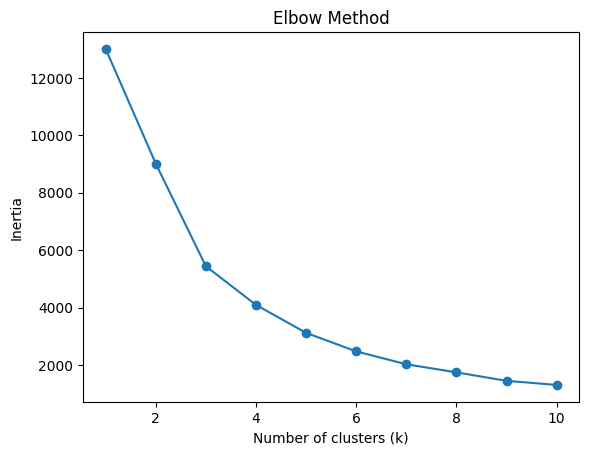

In [22]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(rfm_scaled)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [23]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

rfm.head()

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,326,1,77183.60,0
12347.0,2,7,4310.00,1
12348.0,75,4,1797.24,1
12349.0,19,1,1757.55,1
12350.0,310,1,334.40,0


In [24]:
cluster_summary = rfm.groupby("Cluster").agg(
    Customers=("Recency", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

cluster_summary

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,1082,247.11,1.58,631.42
1,3230,41.45,4.67,1855.94
2,26,6.04,66.42,85904.35


In [25]:
segment_names = {
    0: "Low Engagement",
    1: "Regular Customers",
    2: "High Value Customers"
}

rfm["Segment"] = rfm["Cluster"].map(segment_names)

rfm[["Recency", "Frequency", "Monetary", "Cluster", "Segment"]].head()

,Recency,Frequency,Monetary,Cluster,Segment
CustomerID,,,,,
12346.0,326,1,77183.60,0,Low Engagement
12347.0,2,7,4310.00,1,Regular Customers
12348.0,75,4,1797.24,1,Regular Customers
12349.0,19,1,1757.55,1,Regular Customers
12350.0,310,1,334.40,0,Low Engagement


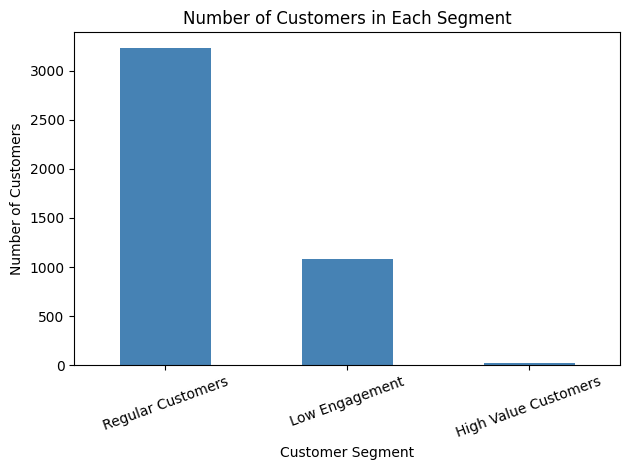

In [26]:
import matplotlib.pyplot as plt

rfm["Segment"].value_counts().plot(kind="bar", color="steelblue")
plt.title("Number of Customers in Each Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [27]:
rfm.groupby("Segment")[["Recency", "Frequency", "Monetary"]].mean().round(2)

,Recency,Frequency,Monetary
Segment,,,
High Value Customers,6.04,66.42,85904.35
Low Engagement,247.11,1.58,631.42
Regular Customers,41.45,4.67,1855.94


In [28]:
rfm.groupby("Segment")[["Recency", "Frequency", "Monetary"]].mean().round(2)

,Recency,Frequency,Monetary
Segment,,,
High Value Customers,6.04,66.42,85904.35
Low Engagement,247.11,1.58,631.42
Regular Customers,41.45,4.67,1855.94


## Customer Segmentation Findings

- **Low Engagement:** 1,082 customers. They purchased infrequently and their last purchase was, on average, about 247 days ago.
- **Regular Customers:** 3,230 customers. They purchased more recently, averaging about 4.67 invoices and 1,855.94 in total spend per customer.
- **High Value Customers:** 26 customers. They purchased recently and had the highest average frequency and spend. This is a small, high-value segment that may deserve personalized offers and retention efforts.

The customer groups were identified using K-Means clustering on Recency, Frequency, and Monetary (RFM) values. The Elbow Method suggested using three clusters.

In [29]:
rfm.to_csv("customer_segments.csv", index=True)
print("Saved customer_segments.csv")

Saved customer_segments.csv


In [30]:
print(df.shape)
print(df.head())

(397884, 9)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  TotalPrice  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom       15.30  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom       20.34  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom       22.00  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom       20.34  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom       20.34  


In [31]:
rfm.to_csv("customer_segments.csv", index=True)
print("Saved customer_segments.csv")

Saved customer_segments.csv
